In [1]:
# ============================================================
# CELL 1 — IMPORTS
# Faithful reproduction of supplied GitHub HBF implementation
# ============================================================

import os
import math
import json
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("=" * 80)
print("ORIGINAL GITHUB HBF — FERETD EXPERIMENT")
print("=" * 80)

print("NumPy version :", np.__version__)
print("Seed          :", SEED)

ORIGINAL GITHUB HBF — FERETD EXPERIMENT
NumPy version : 2.1.3
Seed          : 42


In [2]:
# ============================================================
# CELL 2 — INSTALL FNV PACKAGE USED BY ORIGINAL CODE
# ============================================================

!pip install -q fnv

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 599.8 kB/s eta 0:00:00 0:00:01
  Preparing metadata (setup.py) ... done


In [3]:
# ============================================================
# CELL 2B — VERIFY FNV
# ============================================================

import fnv

test = fnv.hash(
    b"test",
    bits=32
)

print("FNV test output:", test)
print("✓ fnv package ready")

FNV test output: 2949673445
✓ fnv package ready


In [4]:
# ============================================================
# CELL 3 — LOCATE PREPROCESSED FERETD FILES
# ============================================================

INPUT_ROOT = Path("/kaggle/input")


def find_one(filename):

    matches = list(
        INPUT_ROOT.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}"
        )

    if len(matches) > 1:
        print(
            f"WARNING: multiple copies found for {filename}:"
        )

        for m in matches:
            print(" ", m)

    return matches[0]


ENROLLMENT_FILE = find_one(
    "enrollment_templates_4900bit.npy"
)

QUERY_FILE = find_one(
    "query_templates_4900bit.npy"
)

ENROLLMENT_META_FILE = find_one(
    "enrollment_metadata.csv"
)

QUERY_META_FILE = find_one(
    "query_metadata.csv"
)


print("=" * 80)
print("FILES")
print("=" * 80)

print("Enrollment:")
print(ENROLLMENT_FILE)

print("\nQuery:")
print(QUERY_FILE)

print("\nEnrollment metadata:")
print(ENROLLMENT_META_FILE)

print("\nQuery metadata:")
print(QUERY_META_FILE)

FILES
Enrollment:
/kaggle/input/datasets/mashfiqrizvee/fered/enrollment/enrollment_templates_4900bit.npy

Query:
/kaggle/input/datasets/mashfiqrizvee/fered/query/query_templates_4900bit.npy

Enrollment metadata:
/kaggle/input/datasets/mashfiqrizvee/fered/metadata/enrollment_metadata.csv

Query metadata:
/kaggle/input/datasets/mashfiqrizvee/fered/metadata/query_metadata.csv


In [5]:
# ============================================================
# CELL 4 — LOAD DATA
# ============================================================

enrollment_np = np.load(
    ENROLLMENT_FILE
).astype(np.uint8)

query_np = np.load(
    QUERY_FILE
).astype(np.uint8)


enrollment_meta = pd.read_csv(
    ENROLLMENT_META_FILE,
    dtype={"identity": str}
)

query_meta = pd.read_csv(
    QUERY_META_FILE,
    dtype={"identity": str}
)


print("=" * 80)
print("LOADED DATA")
print("=" * 80)

print(
    "Enrollment shape :",
    enrollment_np.shape
)

print(
    "Query shape      :",
    query_np.shape
)

print(
    "Enrollment bits  :",
    np.unique(enrollment_np)
)

print(
    "Query bits       :",
    np.unique(query_np)
)

print("\nQuery composition:")

print(
    query_meta[
        "query_type"
    ].value_counts()
)

LOADED DATA
Enrollment shape : (993, 4900)
Query shape      : (1000, 4900)
Enrollment bits  : [0 1]
Query bits       : [0 1]

Query composition:
query_type
exact       400
second      300
impostor    300
Name: count, dtype: int64


In [6]:
# ============================================================
# CELL 5 — CONVERT NPY BITS TO ORIGINAL GITHUB STRING FORMAT
# ============================================================

def bits_to_string(row):

    return "".join(
        "1" if bit else "0"
        for bit in row
    )


enrollment_data = [
    bits_to_string(row)
    for row in enrollment_np
]

query_data = [
    bits_to_string(row)
    for row in query_np
]


print("=" * 80)
print("GITHUB INPUT FORMAT")
print("=" * 80)

print(
    "Enrollment templates:",
    len(enrollment_data)
)

print(
    "Query templates     :",
    len(query_data)
)

print(
    "Template length     :",
    len(enrollment_data[0])
)

print(
    "Python type         :",
    type(enrollment_data[0])
)

print(
    "\nFirst 80 bits:"
)

print(
    enrollment_data[0][:80]
)


assert len(enrollment_data[0]) == 4900
assert len(query_data[0]) == 4900

GITHUB INPUT FORMAT
Enrollment templates: 993
Query templates     : 1000
Template length     : 4900
Python type         : <class 'str'>

First 80 bits:
00000000000000000000000000000000000000000000000000000000000000000000000000000000


In [7]:
# ============================================================
# CELL 6 — ORIGINAL GITHUB PARAMETERS
# ============================================================

n = len(
    enrollment_data
)

P = 4900

# ------------------------------------------------------------
# EXACT values used by step_maincode.py
# ------------------------------------------------------------

requiredSizeOfBF = 140530
requiredHashNo = 4

total_level = 3

d = [
    0,
    1,
    2
]

d_l = [
    32,
    32 * 13,
    4900
]

d_BFs = [
    153,
    11,
    1
]

threshold = 21


print("=" * 80)
print("ORIGINAL GITHUB HBF PARAMETERS")
print("=" * 80)

print("Actual enrollment n :", n)
print("Template P          :", P)

print()
print("Bloom-filter m      :", requiredSizeOfBF)
print("Hash functions k    :", requiredHashNo)

print()
print("Levels              :", d)
print("Block sizes         :", d_l)
print("BFs per level       :", d_BFs)
print("Total BFs           :", sum(d_BFs))

print()
print("Decision rule       : authenticated_BFs > 21")


assert sum(d_BFs) == 165

ORIGINAL GITHUB HBF PARAMETERS
Actual enrollment n : 993
Template P          : 4900

Bloom-filter m      : 140530
Hash functions k    : 4

Levels              : [0, 1, 2]
Block sizes         : [32, 416, 4900]
BFs per level       : [153, 11, 1]
Total BFs           : 165

Decision rule       : authenticated_BFs > 21


In [8]:
# ============================================================
# CELL 7 — ORIGINAL GITHUB HASH KEYS
# ============================================================

key = []

key1 = np.arange(
    1,
    requiredHashNo + 1,
    dtype=int
)

for value in key1:

    key.append(
        bin(value)[2:].zfill(8)
    )


print("=" * 80)
print("HASH KEYS")
print("=" * 80)

for i, k_string in enumerate(key):

    print(
        f"Hash {i+1}: {k_string}"
    )

HASH KEYS
Hash 1: 00000001
Hash 2: 00000010
Hash 3: 00000011
Hash 4: 00000100


In [9]:
# ============================================================
# CELL 8 — EXACT HASH PIPELINE FROM step2/step3
# ============================================================

bits_to_take = math.floor(
    math.log2(
        requiredSizeOfBF
    )
)

mask_bin = (
    bits_to_take
    * "1"
)

mask_int = int(
    mask_bin,
    2
)


print("=" * 80)
print("GITHUB HASH RANGE PARAMETERS")
print("=" * 80)

print(
    "m                 :",
    requiredSizeOfBF
)

print(
    "floor(log2(m))    :",
    bits_to_take
)

print(
    "mask integer      :",
    mask_int
)

print(
    "actual index max  :",
    mask_int
)

GITHUB HASH RANGE PARAMETERS
m                 : 140530
floor(log2(m))    : 17
mask integer      : 131071
actual index max  : 131071


In [10]:
# ============================================================
# CELL 9 — ORIGINAL GITHUB HASH FUNCTION
# ============================================================

def original_github_hashes(
    template_segment
):
    """
    Faithful implementation of step2_enrollment.py /
    step3_query_perform.py.

    template_segment must be a Python string of 0/1 characters.
    """

    outputs = []

    for key_string in key:

        # ---------------------------------------------
        # Original:
        # temp1_key = bytes(str(key[i]), 'utf-8')
        # ---------------------------------------------
        temp_key = bytes(
            str(key_string),
            "utf-8"
        )

        # ---------------------------------------------
        # Original biometric segment
        # ---------------------------------------------
        temp_msg = bytes(
            template_segment,
            "utf-8"
        )

        # ---------------------------------------------
        # SHA256(message + key).hexdigest()
        # ---------------------------------------------
        hash_sha = hashlib.sha256(
            temp_msg + temp_key
        ).hexdigest()

        # ASCII representation of SHA hex output
        sha_as_bytes = bytes(
            hash_sha,
            "utf-8"
        )

        # ---------------------------------------------
        # 32-bit FNV
        # ---------------------------------------------
        hash_fnv_raw = fnv.hash(
            sha_as_bytes,
            bits=32
        )

        # Exact behavior from original code
        hash_fnv_bin_32bit = (
            "{0:32b}".format(
                hash_fnv_raw
            )
        )

        msg_int = int(
            hash_fnv_bin_32bit,
            2
        )

        # ---------------------------------------------
        # XOR folding
        # ---------------------------------------------
        msg_bitshift = (
            msg_int
            >> bits_to_take
        )

        xor_int = (
            msg_bitshift
            ^ msg_int
        )

        # ---------------------------------------------
        # bit mask = final BF index
        # ---------------------------------------------
        masking = (
            xor_int
            & mask_int
        )

        outputs.append(
            int(masking)
        )

    return outputs

In [11]:
# ============================================================
# CELL 10 — HASH SANITY TEST
# ============================================================

test_segment = enrollment_data[
    0
][0:32]

h1 = original_github_hashes(
    test_segment
)

h2 = original_github_hashes(
    test_segment
)


print("=" * 80)
print("ORIGINAL HASH SANITY TEST")
print("=" * 80)

print(
    "Segment:",
    test_segment
)

print(
    "Indexes:",
    h1
)

print(
    "Number of hashes:",
    len(h1)
)

print(
    "Min:",
    min(h1)
)

print(
    "Max:",
    max(h1)
)


assert h1 == h2
assert len(h1) == 4

assert all(
    0 <= x <= mask_int
    for x in h1
)

print("\n✓ Exact GitHub-style hashing is deterministic.")

ORIGINAL HASH SANITY TEST
Segment: 00000000000000000000000000000000
Indexes: [45028, 67237, 40399, 95545]
Number of hashes: 4
Min: 40399
Max: 95545

✓ Exact GitHub-style hashing is deterministic.


In [12]:
# ============================================================
# CELL 11 — ORIGINAL HBF SEGMENTATION
# ============================================================

def segment_template_original(
    template
):

    levels = []

    for level in range(
        total_level
    ):

        block_len = d_l[
            level
        ]

        n_bfs = d_BFs[
            level
        ]

        level_blocks = []

        c1 = 0

        for j in range(
            n_bfs
        ):

            block = template[
                c1:
                c1 + block_len
            ]

            level_blocks.append(
                block
            )

            c1 += block_len

        levels.append(
            level_blocks
        )

    return levels

In [13]:
# ============================================================
# CELL 12 — SEGMENTATION CHECK
# ============================================================

example_levels = segment_template_original(
    enrollment_data[0]
)

print("=" * 80)
print("SEGMENTATION CHECK")
print("=" * 80)

for level in range(3):

    lengths = [
        len(x)
        for x in example_levels[
            level
        ]
    ]

    print(
        f"Level {level}: "
        f"{len(lengths)} BFs | "
        f"block lengths={sorted(set(lengths))}"
    )

print()

print(
    "Level 0 covered:",
    153 * 32
)

print(
    "Level 1 covered:",
    11 * 416
)

print(
    "Level 2 covered:",
    4900
)

SEGMENTATION CHECK
Level 0: 153 BFs | block lengths=[32]
Level 1: 11 BFs | block lengths=[416]
Level 2: 1 BFs | block lengths=[4900]

Level 0 covered: 4896
Level 1 covered: 4576
Level 2 covered: 4900


In [14]:
# ============================================================
# CELL 13 — ORIGINAL GITHUB HBF ENROLLMENT
# ============================================================

def enroll_original_hbf(
    enrollment_templates
):

    HBF = []

    # --------------------------------------------------------
    # Initialize [level][BF][m]
    # --------------------------------------------------------

    for level in range(
        total_level
    ):

        level_filters = []

        for _ in range(
            d_BFs[level]
        ):

            bf = np.zeros(
                requiredSizeOfBF,
                dtype=np.uint8
            )

            level_filters.append(
                bf
            )

        HBF.append(
            level_filters
        )


    # --------------------------------------------------------
    # Enroll template by template
    # --------------------------------------------------------

    for template in tqdm(
        enrollment_templates,
        desc="Enrolling templates"
    ):

        segmented = segment_template_original(
            template
        )

        for level in range(
            total_level
        ):

            for bf_idx, block in enumerate(
                segmented[level]
            ):

                hash_outputs = original_github_hashes(
                    block
                )

                for position in hash_outputs:

                    HBF[
                        level
                    ][
                        bf_idx
                    ][
                        position
                    ] = 1

    return HBF

In [15]:
# ============================================================
# CELL 14 — ENROLL ALL 993 FERETD TEMPLATES
# ============================================================

HBF_enrolled = enroll_original_hbf(
    enrollment_data
)

print("\n✓ Enrollment complete.")

Enrolling templates:   0%|          | 0/993 [00:00<?, ?it/s]


✓ Enrollment complete.


In [16]:
# ============================================================
# CELL 15 — BF OCCUPANCY
# ============================================================

occupancy_rows = []

for level in range(
    total_level
):

    for bf_idx in range(
        d_BFs[level]
    ):

        bf = HBF_enrolled[
            level
        ][
            bf_idx
        ]

        occupancy_rows.append({
            "level": level,
            "bf": bf_idx,
            "set_bits": int(
                bf.sum()
            ),
            "occupancy": float(
                bf.mean()
            )
        })


occupancy_df = pd.DataFrame(
    occupancy_rows
)


print("=" * 80)
print("ORIGINAL HBF OCCUPANCY")
print("=" * 80)

display(
    occupancy_df
    .groupby("level")[
        "occupancy"
    ]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
    .round(6)
)

ORIGINAL HBF OCCUPANCY


,mean,std,min,max
level,,,,
0,0.009664,0.009335,0.000028,0.026478
1,0.022242,0.011113,0.000028,0.027909
2,0.027859,NaN,0.027859,0.027859


In [17]:
# ============================================================
# CELL 16 — ORIGINAL GITHUB HBF QUERY
# ============================================================

def query_original_hbf(
    template
):

    segmented = segment_template_original(
        template
    )

    authenticated_by_level = []

    total_authenticated = 0

    for level in range(
        total_level
    ):

        level_results = []

        for bf_idx, block in enumerate(
            segmented[level]
        ):

            indices = original_github_hashes(
                block
            )

            authenticated = all(
                HBF_enrolled[
                    level
                ][
                    bf_idx
                ][
                    position
                ] == 1

                for position in indices
            )

            level_results.append(
                authenticated
            )

            if authenticated:
                total_authenticated += 1

        authenticated_by_level.append(
            level_results
        )

    # IMPORTANT:
    # supplied step_maincode.py uses > threshold
    is_member = (
        total_authenticated
        > threshold
    )

    return (
        total_authenticated,
        is_member,
        authenticated_by_level
    )

In [18]:
# ============================================================
# CELL 17 — EXACT QUERY SANITY CHECK
# ============================================================

exact_idx = query_meta.index[
    query_meta["query_type"]
    == "exact"
][0]

score, decision, level_results = \
    query_original_hbf(
        query_data[
            exact_idx
        ]
    )


print("=" * 80)
print("EXACT QUERY — ORIGINAL GITHUB HBF")
print("=" * 80)

print(
    "Query index       :",
    exact_idx
)

print(
    "Identity          :",
    query_meta.loc[
        exact_idx,
        "identity"
    ]
)

print(
    "Authenticated BFs :",
    score,
    "/ 165"
)

print(
    "Member            :",
    decision
)


print(
    "\nLevel 0:",
    sum(level_results[0]),
    "/ 153"
)

print(
    "Level 1:",
    sum(level_results[1]),
    "/ 11"
)

print(
    "Level 2:",
    sum(level_results[2]),
    "/ 1"
)


assert score == 165

print("\n✓ Exact query authenticates all 165 BFs.")

EXACT QUERY — ORIGINAL GITHUB HBF
Query index       : 0
Identity          : 00597
Authenticated BFs : 165 / 165
Member            : True

Level 0: 153 / 153
Level 1: 11 / 11
Level 2: 1 / 1

✓ Exact query authenticates all 165 BFs.


In [19]:
# ============================================================
# CELL 18 — QUERY ALL 1000 SAMPLES
# ============================================================

result_rows = []

for q_idx, template in enumerate(
    tqdm(
        query_data,
        desc="Querying"
    )
):

    score, member, level_results = \
        query_original_hbf(
            template
        )

    result_rows.append({
        "query_index": q_idx,

        "identity": str(
            query_meta.loc[
                q_idx,
                "identity"
            ]
        ),

        "query_type": query_meta.loc[
            q_idx,
            "query_type"
        ],

        "level0_authenticated": int(
            sum(level_results[0])
        ),

        "level1_authenticated": int(
            sum(level_results[1])
        ),

        "level2_authenticated": int(
            sum(level_results[2])
        ),

        "authenticated_bfs": int(
            score
        ),

        "member_gt21": bool(
            member
        )
    })


results_df = pd.DataFrame(
    result_rows
)

print("\n✓ Finished querying.")

Querying:   0%|          | 0/1000 [00:00<?, ?it/s]


✓ Finished querying.


In [20]:
# ============================================================
# CELL 19 — AUTHENTICATED BF STATISTICS
# ============================================================

print("=" * 80)
print("AUTHENTICATED BF DISTRIBUTIONS")
print("=" * 80)

display(
    results_df
    .groupby(
        "query_type"
    )[
        "authenticated_bfs"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ])
    .round(3)
)

AUTHENTICATED BF DISTRIBUTIONS


,count,mean,std,min,median,max
query_type,,,,,,
exact,400,165.000,0.000,165,165.0,165
impostor,300,111.387,7.492,89,111.5,131
second,300,111.200,10.043,86,110.0,140


In [21]:
# ============================================================
# CELL 20 — CATEGORY ACCEPTANCE AT ORIGINAL threshold > 21
# ============================================================

print("=" * 80)
print("CATEGORY ACCEPTANCE — ORIGINAL GITHUB RULE (> 21)")
print("=" * 80)

for category in [
    "exact",
    "second",
    "impostor"
]:

    subset = results_df[
        results_df[
            "query_type"
        ] == category
    ]

    accepted = int(
        subset[
            "member_gt21"
        ].sum()
    )

    total = len(
        subset
    )

    print(
        f"{category:10s}: "
        f"{accepted:3d}/{total:3d} "
        f"({accepted/total*100:6.2f}%)"
    )

CATEGORY ACCEPTANCE — ORIGINAL GITHUB RULE (> 21)
exact     : 400/400 (100.00%)
second    : 300/300 (100.00%)
impostor  : 300/300 (100.00%)


In [22]:
# ============================================================
# CELL 21 — FULL THRESHOLD SWEEP
# Original GitHub decision rule:
#     member if authenticated_bfs > threshold
# ============================================================

threshold_rows = []

genuine_mask = results_df[
    "query_type"
].isin([
    "exact",
    "second"
])

impostor_mask = (
    results_df["query_type"]
    == "impostor"
)

for threshold in range(
    0,
    166
):

    pred_member = (
        results_df[
            "authenticated_bfs"
        ] > threshold
    )

    TP = int(
        (
            pred_member
            & genuine_mask
        ).sum()
    )

    FN = int(
        (
            (~pred_member)
            & genuine_mask
        ).sum()
    )

    FP = int(
        (
            pred_member
            & impostor_mask
        ).sum()
    )

    TN = int(
        (
            (~pred_member)
            & impostor_mask
        ).sum()
    )

    TAR = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    FRR = (
        FN / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    FAR = (
        FP / (FP + TN)
        if (FP + TN) > 0
        else 0
    )

    TNR = (
        TN / (FP + TN)
        if (FP + TN) > 0
        else 0
    )

    ACC = (
        (TP + TN)
        / len(results_df)
    )

    BACC = (
        TAR + TNR
    ) / 2

    threshold_rows.append({
        "threshold": threshold,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "TAR": TAR,
        "FRR": FRR,
        "FAR": FAR,
        "TNR": TNR,
        "ACC": ACC,
        "BACC": BACC
    })


threshold_df = pd.DataFrame(
    threshold_rows
)

print(
    "Threshold sweep complete:",
    len(threshold_df),
    "thresholds"
)

Threshold sweep complete: 166 thresholds


In [23]:
# ============================================================
# CELL 22 — DISPLAY ALL THRESHOLDS
# ============================================================

threshold_display = (
    threshold_df.copy()
)

for col in [
    "TAR",
    "FRR",
    "FAR",
    "TNR",
    "ACC",
    "BACC"
]:
    threshold_display[col] = (
        threshold_display[col]
        * 100
    )

display(
    threshold_display.round(2)
)

,threshold,TP,FN,FP,TN,TAR,FRR,FAR,TNR,ACC,BACC
0,0,700,0,300,0,100.00,0.00,100.0,0.0,70.0,50.00
1,1,700,0,300,0,100.00,0.00,100.0,0.0,70.0,50.00
2,2,700,0,300,0,100.00,0.00,100.0,0.0,70.0,50.00
3,3,700,0,300,0,100.00,0.00,100.0,0.0,70.0,50.00
4,4,700,0,300,0,100.00,0.00,100.0,0.0,70.0,50.00
...,...,...,...,...,...,...,...,...,...,...,...
161,161,400,300,0,300,57.14,42.86,0.0,100.0,70.0,78.57
162,162,400,300,0,300,57.14,42.86,0.0,100.0,70.0,78.57
163,163,400,300,0,300,57.14,42.86,0.0,100.0,70.0,78.57
164,164,400,300,0,300,57.14,42.86,0.0,100.0,70.0,78.57


In [24]:
# ============================================================
# CELL 23 — BEST BALANCED ACCURACY
# ============================================================

best_idx = threshold_df[
    "BACC"
].idxmax()

best_row = threshold_df.loc[
    best_idx
]

print("=" * 80)
print("BEST BALANCED-ACCURACY THRESHOLD")
print("=" * 80)

print(
    "Threshold :",
    int(best_row["threshold"])
)

print(
    f"TAR       : {best_row['TAR']*100:.2f}%"
)

print(
    f"FRR       : {best_row['FRR']*100:.2f}%"
)

print(
    f"FAR       : {best_row['FAR']*100:.2f}%"
)

print(
    f"TNR       : {best_row['TNR']*100:.2f}%"
)

print(
    f"ACC       : {best_row['ACC']*100:.2f}%"
)

print(
    f"BACC      : {best_row['BACC']*100:.2f}%"
)

BEST BALANCED-ACCURACY THRESHOLD
Threshold : 131
TAR       : 58.86%
FRR       : 41.14%
FAR       : 0.00%
TNR       : 100.00%
ACC       : 71.20%
BACC      : 79.43%


In [25]:
# ============================================================
# CELL 24 — APPROXIMATE EER OPERATING POINT
# ============================================================

threshold_df[
    "eer_gap"
] = np.abs(
    threshold_df["FAR"]
    -
    threshold_df["FRR"]
)

eer_idx = threshold_df[
    "eer_gap"
].idxmin()

eer_row = threshold_df.loc[
    eer_idx
]

approx_eer = (
    eer_row["FAR"]
    +
    eer_row["FRR"]
) / 2

print("=" * 80)
print("APPROXIMATE EER OPERATING POINT")
print("=" * 80)

print(
    "Threshold :",
    int(eer_row["threshold"])
)

print(
    f"FAR       : {eer_row['FAR']*100:.2f}%"
)

print(
    f"FRR       : {eer_row['FRR']*100:.2f}%"
)

print(
    f"Approx EER: {approx_eer*100:.2f}%"
)

APPROXIMATE EER OPERATING POINT
Threshold : 115
FAR       : 29.00%
FRR       : 29.14%
Approx EER: 29.07%


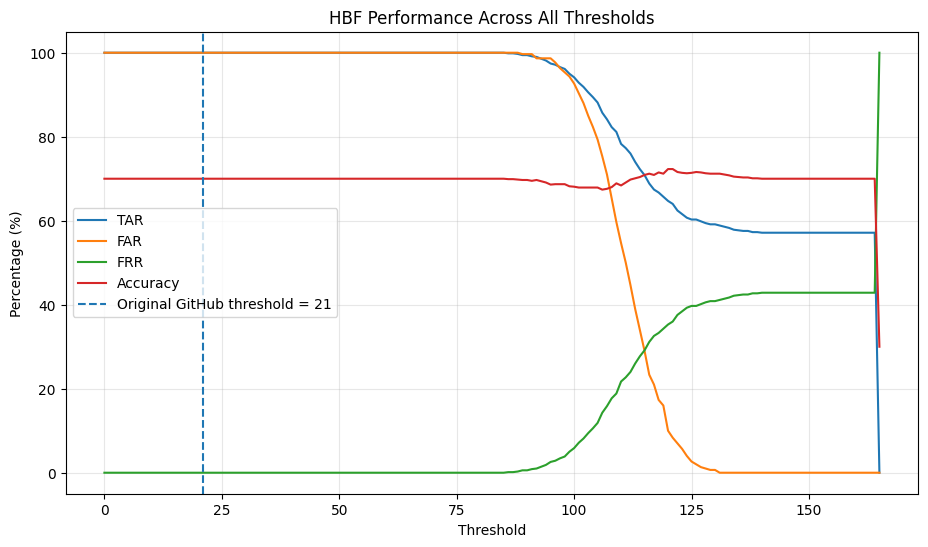

In [26]:
# ============================================================
# CELL 25 — METRICS VS THRESHOLD
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["TAR"] * 100,
    label="TAR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["FAR"] * 100,
    label="FAR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["FRR"] * 100,
    label="FRR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["ACC"] * 100,
    label="Accuracy"
)

plt.axvline(
    21,
    linestyle="--",
    label="Original GitHub threshold = 21"
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Percentage (%)"
)

plt.title(
    "HBF Performance Across All Thresholds"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

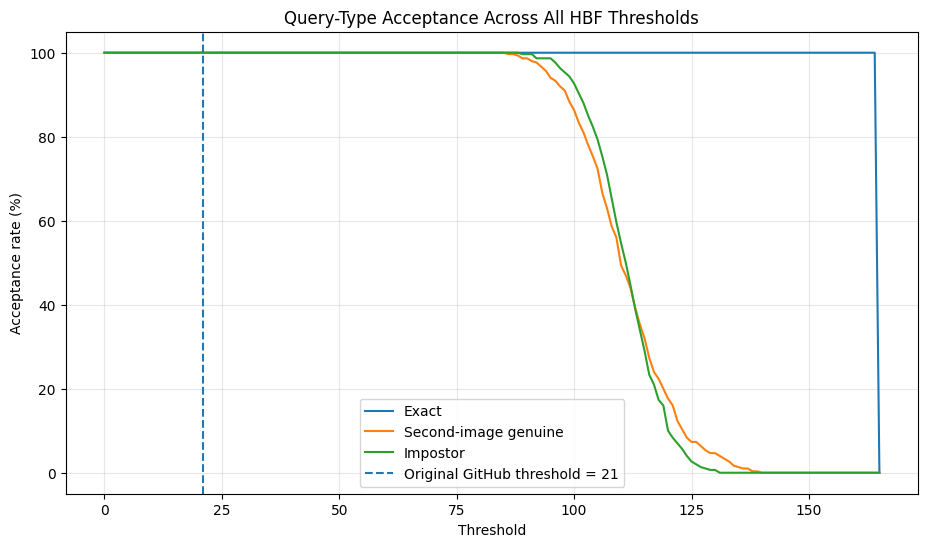

In [27]:
# ============================================================
# CELL 26 — CATEGORY ACCEPTANCE VS THRESHOLD
# ============================================================

category_rows = []

for threshold in range(
    0,
    166
):

    row = {
        "threshold": threshold
    }

    for category in [
        "exact",
        "second",
        "impostor"
    ]:

        subset = results_df[
            results_df["query_type"]
            == category
        ]

        accepted = (
            subset["authenticated_bfs"]
            > threshold
        ).mean()

        row[
            f"{category}_acceptance"
        ] = accepted

    category_rows.append(
        row
    )


category_threshold_df = pd.DataFrame(
    category_rows
)

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    category_threshold_df["threshold"],
    category_threshold_df[
        "exact_acceptance"
    ] * 100,
    label="Exact"
)

plt.plot(
    category_threshold_df["threshold"],
    category_threshold_df[
        "second_acceptance"
    ] * 100,
    label="Second-image genuine"
)

plt.plot(
    category_threshold_df["threshold"],
    category_threshold_df[
        "impostor_acceptance"
    ] * 100,
    label="Impostor"
)

plt.axvline(
    21,
    linestyle="--",
    label="Original GitHub threshold = 21"
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Acceptance rate (%)"
)

plt.title(
    "Query-Type Acceptance Across All HBF Thresholds"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Reformulated

In [28]:
# ============================================================
# PAPER-FORMULA HBF PARAMETERS FOR ACTUAL FERETD ENROLLMENT
# ============================================================

import math
import numpy as np
from scipy.stats import binom

# ------------------------------------------------------------
# Dataset / paper assumptions
# ------------------------------------------------------------

n = len(enrollment_data)      # should be 993
P = 4900

fp = 0.10
e_over_P = 0.16
prob_flip_level0 = 0.995

# ------------------------------------------------------------
# Level-0 block length
# Paper equation:
# 1 - (1-e/P)^l0 = 0.995
# ------------------------------------------------------------

l0_raw = (
    math.log(1 - prob_flip_level0)
    /
    math.log(1 - e_over_P)
)

# Paper implementation uses ~32
l0 = 32

# ------------------------------------------------------------
# Bloom-filter size
# FP ≈ 0.6185^(m/n)
# ------------------------------------------------------------

m_raw = (
    math.log(fp)
    /
    math.log(0.6185)
) * n

m = math.ceil(m_raw)

# ------------------------------------------------------------
# Optimal number of hash functions
# IMPORTANT: source code uses CEIL
# ------------------------------------------------------------

k_raw = (
    m * math.log(2)
    / n
)

k = math.ceil(k_raw)

# ------------------------------------------------------------
# HBF threshold calculation from step1b.py
# ------------------------------------------------------------

pbf = 1 - (
    fp ** (1 / k)
)

p_oneBF = (
    1 - pbf
) ** k

fp_HBF = fp - 0.0001

N_init = math.ceil(
    P / l0_raw
)

N_list = list(
    range(
        N_init,
        N_init + 11
    )
)

X = []

for temp_N in N_list:

    temp_x = binom.ppf(
        1 - fp_HBF,
        temp_N,
        p_oneBF
    )

    X.append(temp_x)

Nt = int(min(X))

# ------------------------------------------------------------
# Paper hierarchy
# ------------------------------------------------------------

w = 13

block_sizes = [
    32,
    32 * w,
    4900
]

bf_counts = [
    153,
    11,
    1
]

N_total = sum(
    bf_counts
)

print("=" * 80)
print("PAPER-FORMULA HBF PARAMETERS — FERETD")
print("=" * 80)

print(f"Enrollment n             : {n}")
print(f"Template length P        : {P}")

print()
print(f"Raw l0                   : {l0_raw:.4f}")
print(f"Implemented l0           : {l0}")

print()
print(f"Raw BF size m            : {m_raw:.4f}")
print(f"BF size m                : {m}")

print(f"Raw k                    : {k_raw:.4f}")
print(f"Hash functions k         : {k}")

print()
print(f"w                         : {w}")
print(f"Block sizes              : {block_sizes}")
print(f"BFs per level            : {bf_counts}")
print(f"Total BFs                : {N_total}")

print()
print(f"Calculated Nt            : {Nt}")

print("\nBinomial candidates:")
for N_, X_ in zip(N_list, X):
    print(f"N={N_:3d} -> Nt={X_:.0f}")

PAPER-FORMULA HBF PARAMETERS — FERETD
Enrollment n             : 993
Template length P        : 4900

Raw l0                   : 30.3884
Implemented l0           : 32

Raw BF size m            : 4758.9312
BF size m                : 4759
Raw k                    : 3.3219
Hash functions k         : 4

w                         : 13
Block sizes              : [32, 416, 4900]
BFs per level            : [153, 11, 1]
Total BFs                : 165

Calculated Nt            : 21

Binomial candidates:
N=162 -> Nt=21
N=163 -> Nt=21
N=164 -> Nt=21
N=165 -> Nt=22
N=166 -> Nt=22
N=167 -> Nt=22
N=168 -> Nt=22
N=169 -> Nt=22
N=170 -> Nt=22
N=171 -> Nt=22
N=172 -> Nt=22


In [29]:
# ============================================================
# CELL 1 — FINAL PAPER-DERIVED HBF PARAMETERS
# ============================================================

requiredSizeOfBF = 4759
requiredHashNo = 4

total_level = 3
d = [0, 1, 2]

d_l = [
    32,
    416,
    4900
]

d_BFs = [
    153,
    11,
    1
]

threshold = 21

print("=" * 80)
print("FINAL HBF PARAMETERS")
print("=" * 80)

print("m              :", requiredSizeOfBF)
print("k              :", requiredHashNo)
print("block sizes    :", d_l)
print("BFs per level  :", d_BFs)
print("total BFs      :", sum(d_BFs))
print("threshold Nt   :", threshold)

FINAL HBF PARAMETERS
m              : 4759
k              : 4
block sizes    : [32, 416, 4900]
BFs per level  : [153, 11, 1]
total BFs      : 165
threshold Nt   : 21


In [30]:
# ============================================================
# CELL 2 — ORIGINAL GITHUB HASH SETTINGS
# ============================================================

bits_to_take = math.floor(
    math.log2(requiredSizeOfBF)
)

mask_bin = bits_to_take * "1"
mask_int = int(mask_bin, 2)

key = []

for value in np.arange(
    1,
    requiredHashNo + 1,
    dtype=int
):
    key.append(
        bin(value)[2:].zfill(8)
    )

print("=" * 80)
print("HASH SETTINGS")
print("=" * 80)

print("bits_to_take :", bits_to_take)
print("mask_int     :", mask_int)
print("keys         :", key)

HASH SETTINGS
bits_to_take : 12
mask_int     : 4095
keys         : ['00000001', '00000010', '00000011', '00000100']


In [31]:
# ============================================================
# CELL 3 — ORIGINAL GITHUB SHA256 + FNV HASH
# ============================================================

def original_github_hashes(
    template_segment
):

    outputs = []

    for key_string in key:

        temp_key = bytes(
            str(key_string),
            "utf-8"
        )

        temp_msg = bytes(
            template_segment,
            "utf-8"
        )

        sha_hex = hashlib.sha256(
            temp_msg + temp_key
        ).hexdigest()

        sha_bytes = bytes(
            sha_hex,
            "utf-8"
        )

        fnv_raw = fnv.hash(
            sha_bytes,
            bits=32
        )

        fnv_bin = (
            "{0:32b}".format(
                fnv_raw
            )
        )

        msg_int = int(
            fnv_bin,
            2
        )

        msg_bitshift = (
            msg_int
            >> bits_to_take
        )

        xor_int = (
            msg_bitshift
            ^ msg_int
        )

        masking = (
            xor_int
            & mask_int
        )

        outputs.append(
            int(masking)
        )

    return outputs

In [32]:
# ============================================================
# CELL 4 — ORIGINAL HBF SEGMENTATION
# ============================================================

def segment_template_original(
    template
):

    levels = []

    for level in range(
        total_level
    ):

        block_len = d_l[level]
        n_bfs = d_BFs[level]

        level_blocks = []

        c1 = 0

        for _ in range(n_bfs):

            block = template[
                c1:c1 + block_len
            ]

            level_blocks.append(
                block
            )

            c1 += block_len

        levels.append(
            level_blocks
        )

    return levels

In [33]:
# ============================================================
# CELL 5 — HBF ENROLLMENT
# ============================================================

def enroll_original_hbf(
    enrollment_templates
):

    HBF = []

    for level in range(
        total_level
    ):

        level_filters = []

        for _ in range(
            d_BFs[level]
        ):

            bf = np.zeros(
                requiredSizeOfBF,
                dtype=np.uint8
            )

            level_filters.append(
                bf
            )

        HBF.append(
            level_filters
        )

    for template in tqdm(
        enrollment_templates,
        desc="Enrolling"
    ):

        segmented = segment_template_original(
            template
        )

        for level in range(
            total_level
        ):

            for bf_idx, block in enumerate(
                segmented[level]
            ):

                indices = original_github_hashes(
                    block
                )

                for position in indices:

                    HBF[level][bf_idx][position] = 1

    return HBF


HBF_enrolled = enroll_original_hbf(
    enrollment_data
)

print("\n✓ Enrollment complete.")

Enrolling:   0%|          | 0/993 [00:00<?, ?it/s]


✓ Enrollment complete.


In [34]:
# ============================================================
# CELL 6 — BLOOM FILTER OCCUPANCY
# ============================================================

occupancy_rows = []

for level in range(
    total_level
):

    for bf_idx in range(
        d_BFs[level]
    ):

        bf = HBF_enrolled[
            level
        ][
            bf_idx
        ]

        occupancy_rows.append({
            "level": level,
            "bf": bf_idx,
            "set_bits": int(bf.sum()),
            "occupancy": float(
                bf.mean()
            )
        })


occupancy_df = pd.DataFrame(
    occupancy_rows
)

print("=" * 80)
print("BF OCCUPANCY")
print("=" * 80)

display(
    occupancy_df
    .groupby("level")["occupancy"]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
    .round(6)
)

BF OCCUPANCY


,mean,std,min,max
level,,,,
0,0.213740,0.192281,0.000841,0.519647
1,0.430572,0.213928,0.000841,0.542341
2,0.538348,NaN,0.538348,0.538348


In [35]:
# ============================================================
# CELL 7 — HBF QUERY FUNCTION
# ============================================================

def query_original_hbf(
    template
):

    segmented = segment_template_original(
        template
    )

    authenticated_by_level = []

    total_authenticated = 0

    for level in range(
        total_level
    ):

        level_results = []

        for bf_idx, block in enumerate(
            segmented[level]
        ):

            indices = original_github_hashes(
                block
            )

            authenticated = all(
                HBF_enrolled[
                    level
                ][
                    bf_idx
                ][
                    position
                ] == 1

                for position in indices
            )

            level_results.append(
                authenticated
            )

            if authenticated:
                total_authenticated += 1

        authenticated_by_level.append(
            level_results
        )

    # Original GitHub rule
    is_member = (
        total_authenticated
        > threshold
    )

    return (
        total_authenticated,
        is_member,
        authenticated_by_level
    )

In [36]:
# ============================================================
# CELL 8 — EXACT QUERY SANITY CHECK
# ============================================================

exact_idx = query_meta.index[
    query_meta["query_type"] == "exact"
][0]

score, member, level_results = \
    query_original_hbf(
        query_data[exact_idx]
    )

print("=" * 80)
print("EXACT QUERY CHECK")
print("=" * 80)

print("Authenticated BFs :", score)
print("Member            :", member)

print(
    "Level 0:",
    sum(level_results[0]),
    "/ 153"
)

print(
    "Level 1:",
    sum(level_results[1]),
    "/ 11"
)

print(
    "Level 2:",
    sum(level_results[2]),
    "/ 1"
)

assert score == 165

print("\n✓ Exact query passed all 165 BFs.")

EXACT QUERY CHECK
Authenticated BFs : 165
Member            : True
Level 0: 153 / 153
Level 1: 11 / 11
Level 2: 1 / 1

✓ Exact query passed all 165 BFs.


In [37]:
# ============================================================
# CELL 9 — RUN ALL 1000 QUERIES
# ============================================================

result_rows = []

for q_idx, template in enumerate(
    tqdm(
        query_data,
        desc="Querying"
    )
):

    score, member, level_results = \
        query_original_hbf(
            template
        )

    result_rows.append({
        "query_index": q_idx,
        "identity": str(
            query_meta.loc[
                q_idx,
                "identity"
            ]
        ),
        "query_type": query_meta.loc[
            q_idx,
            "query_type"
        ],
        "level0_authenticated": int(
            sum(level_results[0])
        ),
        "level1_authenticated": int(
            sum(level_results[1])
        ),
        "level2_authenticated": int(
            sum(level_results[2])
        ),
        "authenticated_bfs": int(
            score
        ),
        "member_gt21": bool(
            member
        )
    })


results_df = pd.DataFrame(
    result_rows
)

print("\n✓ Querying complete.")

Querying:   0%|          | 0/1000 [00:00<?, ?it/s]


✓ Querying complete.


In [38]:
# ============================================================
# CELL 10 — AUTHENTICATED-BF DISTRIBUTION SUMMARY
# ============================================================

summary = (
    results_df
    .groupby(
        "query_type"
    )[
        "authenticated_bfs"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ])
)

display(
    summary.round(3)
)

,count,mean,std,min,median,max
query_type,,,,,,
exact,400,165.000,0.000,165,165.0,165
impostor,300,115.703,7.398,91,116.0,135
second,300,115.717,9.723,91,115.0,143


In [39]:
# ============================================================
# CELL 11 — ORIGINAL THRESHOLD PERFORMANCE
# ============================================================

print("=" * 80)
print("CATEGORY ACCEPTANCE — threshold > 21")
print("=" * 80)

for category in [
    "exact",
    "second",
    "impostor"
]:

    subset = results_df[
        results_df["query_type"]
        == category
    ]

    accepted = int(
        (
            subset["authenticated_bfs"]
            > 21
        ).sum()
    )

    total = len(subset)

    print(
        f"{category:10s}: "
        f"{accepted:3d}/{total:3d} "
        f"({accepted/total*100:6.2f}%)"
    )

CATEGORY ACCEPTANCE — threshold > 21
exact     : 400/400 (100.00%)
second    : 300/300 (100.00%)
impostor  : 300/300 (100.00%)


In [40]:
# ============================================================
# CELL 12 — TAR / FAR / FRR / ACC AT Nt = 21
# ============================================================

genuine_mask = results_df[
    "query_type"
].isin([
    "exact",
    "second"
])

impostor_mask = (
    results_df["query_type"]
    == "impostor"
)

pred_member = (
    results_df[
        "authenticated_bfs"
    ] > 21
)

TP = int(
    (
        pred_member
        & genuine_mask
    ).sum()
)

FN = int(
    (
        (~pred_member)
        & genuine_mask
    ).sum()
)

FP = int(
    (
        pred_member
        & impostor_mask
    ).sum()
)

TN = int(
    (
        (~pred_member)
        & impostor_mask
    ).sum()
)

TAR = TP / (TP + FN)
FRR = FN / (TP + FN)
FAR = FP / (FP + TN)
TNR = TN / (FP + TN)

ACC = (
    (TP + TN)
    / len(results_df)
)

BACC = (
    TAR + TNR
) / 2

print("=" * 80)
print("PERFORMANCE AT Nt = 21")
print("=" * 80)

print(f"TP   : {TP}")
print(f"FN   : {FN}")
print(f"FP   : {FP}")
print(f"TN   : {TN}")

print()
print(f"TAR  : {TAR*100:.2f}%")
print(f"FRR  : {FRR*100:.2f}%")
print(f"FAR  : {FAR*100:.2f}%")
print(f"TNR  : {TNR*100:.2f}%")
print(f"ACC  : {ACC*100:.2f}%")
print(f"BACC : {BACC*100:.2f}%")

PERFORMANCE AT Nt = 21
TP   : 700
FN   : 0
FP   : 300
TN   : 0

TAR  : 100.00%
FRR  : 0.00%
FAR  : 100.00%
TNR  : 0.00%
ACC  : 70.00%
BACC : 50.00%


In [41]:
# ============================================================
# CELL 13 — FULL THRESHOLD SWEEP
# ============================================================

threshold_rows = []

for t in range(
    0,
    166
):

    pred = (
        results_df[
            "authenticated_bfs"
        ] > t
    )

    TP = int(
        (
            pred
            & genuine_mask
        ).sum()
    )

    FN = int(
        (
            (~pred)
            & genuine_mask
        ).sum()
    )

    FP = int(
        (
            pred
            & impostor_mask
        ).sum()
    )

    TN = int(
        (
            (~pred)
            & impostor_mask
        ).sum()
    )

    TAR = TP / (TP + FN)
    FRR = FN / (TP + FN)

    FAR = FP / (FP + TN)
    TNR = TN / (FP + TN)

    ACC = (
        (TP + TN)
        / len(results_df)
    )

    BACC = (
        TAR + TNR
    ) / 2

    threshold_rows.append({
        "threshold": t,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "TAR": TAR,
        "FRR": FRR,
        "FAR": FAR,
        "TNR": TNR,
        "ACC": ACC,
        "BACC": BACC
    })


threshold_df = pd.DataFrame(
    threshold_rows
)

In [42]:
# ============================================================
# CELL 14 — BEST THRESHOLD + APPROXIMATE EER
# ============================================================

best_idx = threshold_df[
    "BACC"
].idxmax()

best_row = threshold_df.loc[
    best_idx
]

threshold_df[
    "eer_gap"
] = np.abs(
    threshold_df["FAR"]
    -
    threshold_df["FRR"]
)

eer_idx = threshold_df[
    "eer_gap"
].idxmin()

eer_row = threshold_df.loc[
    eer_idx
]

approx_eer = (
    eer_row["FAR"]
    +
    eer_row["FRR"]
) / 2


print("=" * 80)
print("BEST BALANCED-ACCURACY THRESHOLD")
print("=" * 80)

print(
    "Threshold :",
    int(best_row["threshold"])
)

print(
    f"TAR       : {best_row['TAR']*100:.2f}%"
)

print(
    f"FAR       : {best_row['FAR']*100:.2f}%"
)

print(
    f"FRR       : {best_row['FRR']*100:.2f}%"
)

print(
    f"ACC       : {best_row['ACC']*100:.2f}%"
)

print(
    f"BACC      : {best_row['BACC']*100:.2f}%"
)


print("\n" + "=" * 80)
print("APPROXIMATE EER")
print("=" * 80)

print(
    "Threshold :",
    int(eer_row["threshold"])
)

print(
    f"FAR       : {eer_row['FAR']*100:.2f}%"
)

print(
    f"FRR       : {eer_row['FRR']*100:.2f}%"
)

print(
    f"EER       : {approx_eer*100:.2f}%"
)

BEST BALANCED-ACCURACY THRESHOLD
Threshold : 135
TAR       : 58.71%
FAR       : 0.00%
FRR       : 41.29%
ACC       : 71.10%
BACC      : 79.36%

APPROXIMATE EER
Threshold : 119
FAR       : 31.00%
FRR       : 28.14%
EER       : 29.57%


In [43]:
# ============================================================
# CELL 15 — THRESHOLD TABLE
# ============================================================

display_df = threshold_df.copy()

for col in [
    "TAR",
    "FRR",
    "FAR",
    "TNR",
    "ACC",
    "BACC"
]:

    display_df[col] = (
        display_df[col]
        * 100
    )

display(
    display_df[
        [
            "threshold",
            "TAR",
            "FRR",
            "FAR",
            "TNR",
            "ACC",
            "BACC"
        ]
    ].round(2)
)

,threshold,TAR,FRR,FAR,TNR,ACC,BACC
0,0,100.00,0.00,100.0,0.0,70.0,50.00
1,1,100.00,0.00,100.0,0.0,70.0,50.00
2,2,100.00,0.00,100.0,0.0,70.0,50.00
3,3,100.00,0.00,100.0,0.0,70.0,50.00
4,4,100.00,0.00,100.0,0.0,70.0,50.00
...,...,...,...,...,...,...,...
161,161,57.14,42.86,0.0,100.0,70.0,78.57
162,162,57.14,42.86,0.0,100.0,70.0,78.57
163,163,57.14,42.86,0.0,100.0,70.0,78.57
164,164,57.14,42.86,0.0,100.0,70.0,78.57


In [44]:
# ============================================================
# CHECK EXACT / SECOND / IMPOSTOR SCORES BEFORE PLOTTING
# ============================================================

print("=" * 80)
print("QUERY SCORE CHECK")
print("=" * 80)

print("\nQuery types present:")
print(results_df["query_type"].value_counts(dropna=False))

for category in ["exact", "second", "impostor"]:

    values = results_df.loc[
        results_df["query_type"] == category,
        "authenticated_bfs"
    ]

    print(f"\n{category.upper()}")
    print("-" * 40)
    print("Count  :", len(values))

    if len(values) > 0:
        print("Min    :", values.min())
        print("Median :", values.median())
        print("Mean   :", values.mean())
        print("Max    :", values.max())

        print(
            "Score=165:",
            int((values == 165).sum())
        )

QUERY SCORE CHECK

Query types present:
query_type
exact       400
second      300
impostor    300
Name: count, dtype: int64

EXACT
----------------------------------------
Count  : 400
Min    : 165
Median : 165.0
Mean   : 165.0
Max    : 165
Score=165: 400

SECOND
----------------------------------------
Count  : 300
Min    : 91
Median : 115.0
Mean   : 115.71666666666667
Max    : 143
Score=165: 0

IMPOSTOR
----------------------------------------
Count  : 300
Min    : 91
Median : 116.0
Mean   : 115.70333333333333
Max    : 135
Score=165: 0


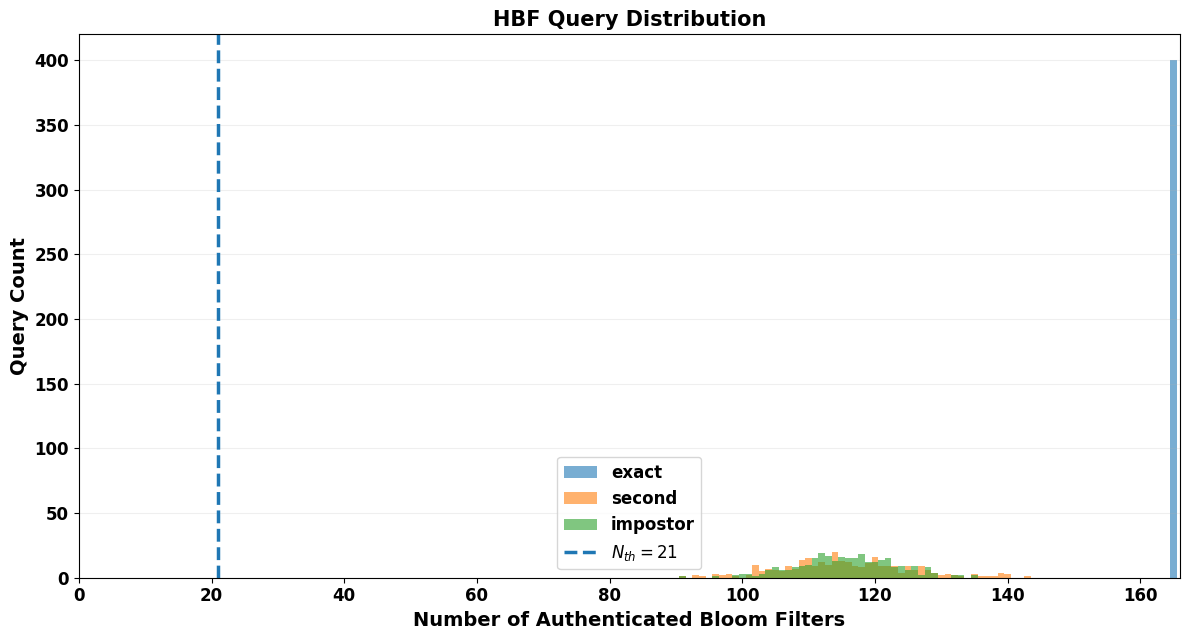

In [45]:
# ============================================================
# FIXED HBF QUERY DISTRIBUTION
# COMMON INTEGER-ALIGNED BINS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Every possible integer HBF score:
# 0, 1, ..., 165
bins = np.arange(
    -0.5,
    166.5,
    1
)

plt.figure(
    figsize=(12, 6.5)
)


for category in [
    "exact",
    "second",
    "impostor"
]:

    values = results_df.loc[
        results_df["query_type"] == category,
        "authenticated_bfs"
    ].to_numpy()

    plt.hist(
        values,
        bins=bins,
        alpha=0.60,
        label=category
    )


plt.axvline(
    21,
    linestyle="--",
    linewidth=2.5,
    label=r"$N_{th}=21$"
)


plt.xlabel(
    "Number of Authenticated Bloom Filters",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Query Count",
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "HBF Query Distribution",
    fontsize=15,
    fontweight="bold"
)


plt.xticks(
    fontsize=12,
    fontweight="bold"
)

plt.yticks(
    fontsize=12,
    fontweight="bold"
)


legend = plt.legend(
    fontsize=12
)

for text in legend.get_texts():
    text.set_fontweight("bold")


plt.xlim(
    0,
    166
)

plt.grid(
    alpha=0.20,
    axis="y"
)

plt.tight_layout()

plt.show()

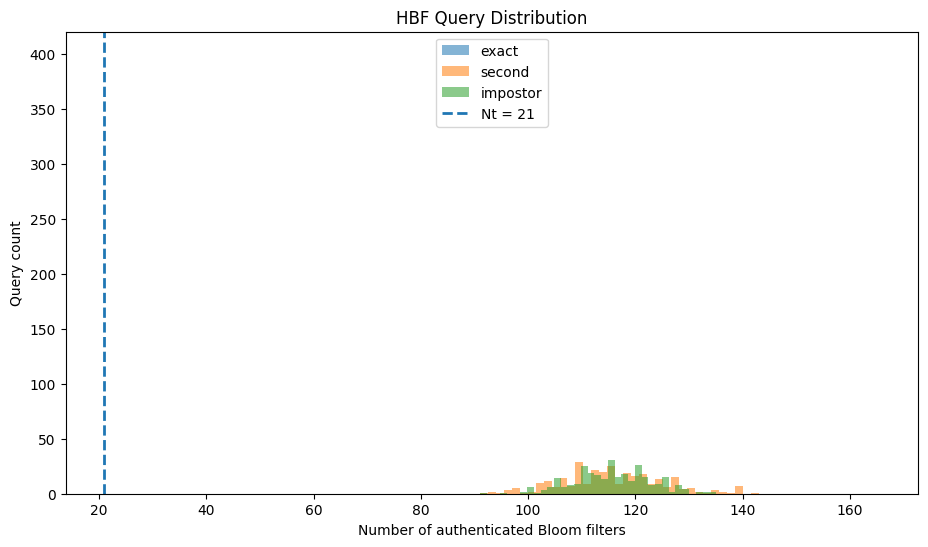

In [46]:
# ============================================================
# CELL 16 — AUTHENTICATED-BF DISTRIBUTIONS
# ============================================================

plt.figure(
    figsize=(11, 6)
)

for category in [
    "exact",
    "second",
    "impostor"
]:

    values = results_df.loc[
        results_df["query_type"]
        == category,
        "authenticated_bfs"
    ]

    plt.hist(
        values,
        bins=35,
        alpha=0.55,
        label=category
    )

plt.axvline(
    21,
    linestyle="--",
    linewidth=2,
    label="Nt = 21"
)

plt.xlabel(
    "Number of authenticated Bloom filters"
)

plt.ylabel(
    "Query count"
)

plt.title(
    "HBF Query Distribution"
)

plt.legend()

plt.show()

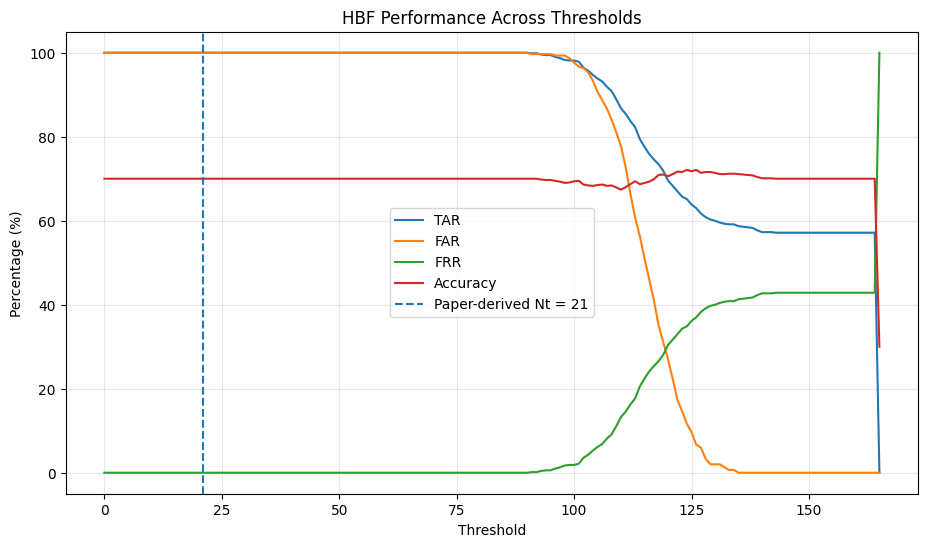

In [47]:
# ============================================================
# CELL 17 — METRICS VS THRESHOLD
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["TAR"] * 100,
    label="TAR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["FAR"] * 100,
    label="FAR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["FRR"] * 100,
    label="FRR"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["ACC"] * 100,
    label="Accuracy"
)

plt.axvline(
    21,
    linestyle="--",
    label="Paper-derived Nt = 21"
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Percentage (%)"
)

plt.title(
    "HBF Performance Across Thresholds"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

# Previous Experiment

In [48]:
# ============================================================
# LOAD + VALIDATE ORIGINAL 4900-BIT STRING TEMPLATES
# ============================================================

import json
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")


def find_exact_file(filename):

    matches = list(
        INPUT_ROOT.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}"
        )

    return matches[0]


ENROLLMENT_TXT = find_exact_file(
    "enrol_template_PinellasFRGC.txt"
)

QUERY_TXT = find_exact_file(
    "query_template_PinellasFRGC.txt"
)


with open(
    ENROLLMENT_TXT,
    "r"
) as f:
    orig_enrollment_data = json.load(f)


with open(
    QUERY_TXT,
    "r"
) as f:
    orig_query_data = json.load(f)


print("=" * 80)
print("DATA LOADED")
print("=" * 80)

print(
    "Enrollment templates :",
    len(orig_enrollment_data)
)

print(
    "Query templates      :",
    len(orig_query_data)
)

print(
    "Type of first enrollment template:",
    type(orig_enrollment_data[0])
)

print(
    "Length of first enrollment template:",
    len(orig_enrollment_data[0])
)

print(
    "Length of first query template:",
    len(orig_query_data[0])
)

DATA LOADED
Enrollment templates : 30000
Query templates      : 906
Type of first enrollment template: <class 'str'>
Length of first enrollment template: 4900
Length of first query template: 4900


In [49]:
# ============================================================
# VALIDATE 30K ENROLLMENT TEMPLATES
# ============================================================

bad_enrollment = []

for i, template in enumerate(
    orig_enrollment_data
):

    valid_length = (
        len(template) == 4900
    )

    valid_binary = (
        set(template)
        <= {"0", "1"}
    )

    if not (
        valid_length
        and valid_binary
    ):
        bad_enrollment.append(
            (
                i,
                len(template),
                sorted(
                    set(template)
                )
            )
        )


print("=" * 80)
print("ENROLLMENT VALIDATION")
print("=" * 80)

print(
    "Total enrollment templates:",
    len(orig_enrollment_data)
)

print(
    "Valid templates:",
    len(orig_enrollment_data)
    - len(bad_enrollment)
)

print(
    "Invalid templates:",
    len(bad_enrollment)
)

if bad_enrollment:

    print(
        "\nFirst few invalid entries:"
    )

    for item in bad_enrollment[:10]:
        print(item)

else:

    print(
        "\n✓ All enrollment templates are valid 4900-bit binary strings."
    )

ENROLLMENT VALIDATION
Total enrollment templates: 30000
Valid templates: 30000
Invalid templates: 0

✓ All enrollment templates are valid 4900-bit binary strings.


In [50]:
# ============================================================
# VALIDATE QUERY TEMPLATES
# ============================================================

bad_query = []

for i, template in enumerate(
    orig_query_data
):

    valid_length = (
        len(template) == 4900
    )

    valid_binary = (
        set(template)
        <= {"0", "1"}
    )

    if not (
        valid_length
        and valid_binary
    ):
        bad_query.append(
            (
                i,
                len(template),
                sorted(
                    set(template)
                )
            )
        )


print("=" * 80)
print("QUERY VALIDATION")
print("=" * 80)

print(
    "Total query templates:",
    len(orig_query_data)
)

print(
    "Valid 4900-bit binary queries:",
    len(orig_query_data)
    - len(bad_query)
)

print(
    "Invalid queries:",
    len(bad_query)
)

if bad_query:

    print(
        "\nFirst few unusual query entries:"
    )

    for item in bad_query[:20]:
        print(item)

else:

    print(
        "\n✓ All queries are valid 4900-bit binary strings."
    )

QUERY VALIDATION
Total query templates: 906
Valid 4900-bit binary queries: 604
Invalid queries: 302

First few unusual query entries:
(604, 13, ['.', '3', '6', '9', '_', 'g', 'i', 'j', 'n', 'p'])
(605, 10, ['.', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(606, 11, ['.', '0', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(607, 12, ['.', '0', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(608, 13, ['.', '0', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(609, 13, ['.', '0', '1', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(610, 13, ['.', '0', '2', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(611, 13, ['.', '0', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(612, 13, ['.', '0', '3', '4', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(613, 13, ['.', '0', '3', '5', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(614, 13, ['.', '0', '3', '6', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(615, 13, ['.', '0', '3', '7', '_', 'g', 'i', 'j', 'n', 'p'])
(616, 13, ['.', '0', '3', '7', '8', '_', 'g', 'i', 'j', 'n', 'p'])
(617, 13, ['.', '0', '3', '7', '9',

In [51]:
# ============================================================
# CELL 20 — EXACT 30K GITHUB PARAMETERS
# ============================================================

N30 = len(
    orig_enrollment_data
)

P30 = 4900


# Exact values in step_maincode.py

M30 = 140530
K30 = 4

LEVELS30 = [
    0,
    1,
    2
]

BLOCK_LENGTHS30 = [
    32,
    32 * 13,
    4900
]

BF_COUNTS30 = [
    153,
    11,
    1
]

NT30 = 21

TOTAL_BFS30 = sum(
    BF_COUNTS30
)


print("=" * 80)
print("ORIGINAL GITHUB HBF PARAMETERS")
print("=" * 80)

print("Enrollment n       :", N30)
print("Template P         :", P30)

print()
print("BF size m          :", M30)
print("Hashes k           :", K30)

print()
print("Block sizes        :", BLOCK_LENGTHS30)
print("BFs per level      :", BF_COUNTS30)
print("Total BFs          :", TOTAL_BFS30)

print()
print("Threshold          :", NT30)
print("Decision rule      : authenticated BFs > 21")


assert TOTAL_BFS30 == 165

ORIGINAL GITHUB HBF PARAMETERS
Enrollment n       : 30000
Template P         : 4900

BF size m          : 140530
Hashes k           : 4

Block sizes        : [32, 416, 4900]
BFs per level      : [153, 11, 1]
Total BFs          : 165

Threshold          : 21
Decision rule      : authenticated BFs > 21


In [52]:
# ============================================================
# CELL 21 — EXACT ORIGINAL HASH PARAMETERS
# ============================================================

BITS_TO_TAKE30 = math.floor(
    math.log2(M30)
)

MASK_BIN30 = (
    BITS_TO_TAKE30
    * "1"
)

MASK_INT30 = int(
    MASK_BIN30,
    2
)


KEYS30 = []

key_values = np.arange(
    1,
    K30 + 1,
    dtype=int
)

for value in key_values:

    key_string = (
        bin(value)[2:]
        .zfill(8)
    )

    KEYS30.append(
        key_string
    )


print("=" * 80)
print("ORIGINAL HASH SETTINGS")
print("=" * 80)

print(
    "floor(log2(m)):",
    BITS_TO_TAKE30
)

print(
    "Mask integer   :",
    MASK_INT30
)

print(
    "Hash keys      :",
    KEYS30
)

print(
    "Largest reachable index:",
    MASK_INT30
)

ORIGINAL HASH SETTINGS
floor(log2(m)): 17
Mask integer   : 131071
Hash keys      : ['00000001', '00000010', '00000011', '00000100']
Largest reachable index: 131071


In [53]:
# ============================================================
# CELL 22 — SHA256 → FNV32 → XOR → MASK
# Exact behavior of supplied GitHub implementation
# ============================================================

def github_hash_30k(
    template_segment
):

    outputs = []

    for key_string in KEYS30:

        temp_key = bytes(
            str(key_string),
            "utf-8"
        )

        temp_msg = bytes(
            template_segment,
            "utf-8"
        )

        # SHA256(message + key)
        hash_sha = hashlib.sha256(
            temp_msg + temp_key
        ).hexdigest()

        # Original code hashes the ASCII hexadecimal digest
        sha_bytes = bytes(
            hash_sha,
            "utf-8"
        )

        # FNV 32-bit
        hash_fnv_raw = fnv.hash(
            sha_bytes,
            bits=32
        )

        # Original source behavior
        hash_fnv_bin = (
            "{0:32b}".format(
                hash_fnv_raw
            )
        )

        msg_int = int(
            hash_fnv_bin,
            2
        )

        # XOR folding
        msg_bitshift = (
            msg_int
            >> BITS_TO_TAKE30
        )

        xor_int = (
            msg_bitshift
            ^ msg_int
        )

        # Final BF index
        masking = (
            xor_int
            & MASK_INT30
        )

        outputs.append(
            int(masking)
        )

    return outputs

In [54]:
# ============================================================
# CELL 23 — HASH SANITY CHECK
# ============================================================

test_segment = (
    orig_enrollment_data[0][0:32]
)

hash_test_1 = github_hash_30k(
    test_segment
)

hash_test_2 = github_hash_30k(
    test_segment
)


print("=" * 80)
print("HASH SANITY CHECK")
print("=" * 80)

print(
    "Input block :",
    test_segment
)

print(
    "Hash outputs:",
    hash_test_1
)


assert hash_test_1 == hash_test_2
assert len(hash_test_1) == 4

assert all(
    0 <= h <= MASK_INT30
    for h in hash_test_1
)

print(
    "\n✓ Original hash function is deterministic."
)

HASH SANITY CHECK
Input block : 10010010111111111100111111111110
Hash outputs: [23404, 21357, 40622, 97435]

✓ Original hash function is deterministic.


In [55]:
# ============================================================
# CELL 24 — ORIGINAL HIERARCHY SEGMENTATION
# ============================================================

def segment_template_30k(
    template
):

    levels = []

    for level in LEVELS30:

        block_length = (
            BLOCK_LENGTHS30[level]
        )

        num_bfs = (
            BF_COUNTS30[level]
        )

        level_blocks = []

        c1 = 0

        for bf_index in range(
            num_bfs
        ):

            block = template[
                c1:
                c1 + block_length
            ]

            level_blocks.append(
                block
            )

            c1 += block_length

        levels.append(
            level_blocks
        )

    return levels

In [56]:
example = segment_template_30k(
    orig_enrollment_data[0]
)

print("=" * 80)
print("SEGMENTATION CHECK")
print("=" * 80)

for level in LEVELS30:

    lengths = [
        len(x)
        for x in example[level]
    ]

    print(
        f"Level {level}: "
        f"{len(lengths)} BFs | "
        f"unique block lengths = "
        f"{sorted(set(lengths))}"
    )

SEGMENTATION CHECK
Level 0: 153 BFs | unique block lengths = [32]
Level 1: 11 BFs | unique block lengths = [416]
Level 2: 1 BFs | unique block lengths = [4900]


In [57]:
# ============================================================
# CELL 25 — INITIALIZE ORIGINAL HBF
# ============================================================

HBF_30K = []

for level in LEVELS30:

    level_filters = []

    for _ in range(
        BF_COUNTS30[level]
    ):

        bf = np.zeros(
            M30,
            dtype=np.uint8
        )

        level_filters.append(
            bf
        )

    HBF_30K.append(
        level_filters
    )


print("=" * 80)
print("HBF INITIALIZED")
print("=" * 80)

print(
    "Level 0:",
    len(HBF_30K[0])
)

print(
    "Level 1:",
    len(HBF_30K[1])
)

print(
    "Level 2:",
    len(HBF_30K[2])
)

print(
    "Total BFs:",
    sum(
        len(x)
        for x in HBF_30K
    )
)

HBF INITIALIZED
Level 0: 153
Level 1: 11
Level 2: 1
Total BFs: 165


In [58]:
# ============================================================
# CELL 26 — ENROLL ALL 30,000 TEMPLATES
# ============================================================

for person_index, template in enumerate(
    tqdm(
        orig_enrollment_data,
        desc="Enrolling 30K templates"
    )
):

    segmented = segment_template_30k(
        template
    )

    for level in LEVELS30:

        for bf_index, block in enumerate(
            segmented[level]
        ):

            hash_outputs = github_hash_30k(
                block
            )

            for position in hash_outputs:

                HBF_30K[
                    level
                ][
                    bf_index
                ][
                    position
                ] = 1


print(
    "\n✓ 30,000 enrollment templates inserted."
)

Enrolling 30K templates:   0%|          | 0/30000 [00:00<?, ?it/s]


✓ 30,000 enrollment templates inserted.


In [59]:
# ============================================================
# CELL 27 — OCCUPANCY DIAGNOSTICS
# ============================================================

occupancy_30k_rows = []

for level in LEVELS30:

    for bf_index in range(
        BF_COUNTS30[level]
    ):

        bf = HBF_30K[
            level
        ][
            bf_index
        ]

        occupancy_30k_rows.append({
            "level": level,
            "bf": bf_index,
            "set_bits": int(
                np.sum(bf)
            ),
            "occupancy": float(
                np.mean(bf)
            )
        })


occupancy_30k_df = pd.DataFrame(
    occupancy_30k_rows
)


print("=" * 80)
print("30K HBF OCCUPANCY")
print("=" * 80)

display(
    occupancy_30k_df
    .groupby("level")["occupancy"]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ])
    .round(6)
)

30K HBF OCCUPANCY


,count,mean,std,min,max
level,,,,,
0,153,0.430605,0.091111,0.197652,0.548360
1,11,0.558826,0.000798,0.557739,0.559994
2,1,0.559240,NaN,0.559240,0.559240


In [60]:
# ============================================================
# CELL 28 — COMPLETE ORIGINAL GITHUB QUERY FUNCTION
# ============================================================

def query_hbf_30k(template):

    segmented = segment_template_30k(
        template
    )

    level_results = []

    total_authenticated = 0

    # --------------------------------------------------------
    # Query every BF in every hierarchy level
    # --------------------------------------------------------

    for level in LEVELS30:

        results_this_level = []

        for bf_index, block in enumerate(
            segmented[level]
        ):

            positions = github_hash_30k(
                block
            )

            # A BF authenticates only if ALL k hash positions are 1
            authenticated = True

            for position in positions:

                if (
                    HBF_30K[
                        level
                    ][
                        bf_index
                    ][
                        position
                    ]
                    != 1
                ):
                    authenticated = False
                    break

            results_this_level.append(
                authenticated
            )

            if authenticated:
                total_authenticated += 1

        level_results.append(
            results_this_level
        )

    # --------------------------------------------------------
    # EXACT original GitHub decision rule:
    #
    # if authenticated_BFs > threshold:
    #     Member
    #
    # threshold = 21
    # --------------------------------------------------------

    is_member = (
        total_authenticated
        > NT30
    )

    # IMPORTANT: return all three outputs
    return (
        total_authenticated,
        is_member,
        level_results
    )


print("✓ query_hbf_30k() redefined successfully.")

✓ query_hbf_30k() redefined successfully.


In [61]:
# ============================================================
# CELL 29 — ENROLLED TEMPLATE SANITY CHECK
# ============================================================

test_template = orig_enrollment_data[0]

score, member, level_results = query_hbf_30k(
    test_template
)

print("=" * 80)
print("KNOWN ENROLLED TEMPLATE — SANITY CHECK")
print("=" * 80)

print("Authenticated BFs :", score, "/ 165")
print("Member (>21)      :", member)

print()
print(
    "Level 0:",
    sum(level_results[0]),
    "/ 153"
)

print(
    "Level 1:",
    sum(level_results[1]),
    "/ 11"
)

print(
    "Level 2:",
    sum(level_results[2]),
    "/ 1"
)

assert score == 165

print(
    "\n✓ Known enrolled template authenticated by all 165 BFs."
)

KNOWN ENROLLED TEMPLATE — SANITY CHECK
Authenticated BFs : 165 / 165
Member (>21)      : True

Level 0: 153 / 153
Level 1: 11 / 11
Level 2: 1 / 1

✓ Known enrolled template authenticated by all 165 BFs.


In [62]:
# ============================================================
# CELL 30 — EXACT QUERY / ENROLLMENT OVERLAP
# ============================================================

enrollment_set_30k = set(
    orig_enrollment_data
)

exact_query_mask = np.array([
    q in enrollment_set_30k
    for q in orig_query_data
])

n_exact_queries = int(
    exact_query_mask.sum()
)

n_nonexact_queries = (
    len(orig_query_data)
    - n_exact_queries
)

print("=" * 80)
print("QUERY / ENROLLMENT EXACT OVERLAP")
print("=" * 80)

print(
    "Total queries            :",
    len(orig_query_data)
)

print(
    "Exact enrolled templates :",
    n_exact_queries
)

print(
    "Non-exact queries        :",
    n_nonexact_queries
)

print(
    "Exact percentage         :",
    f"{n_exact_queries / len(orig_query_data) * 100:.2f}%"
)

QUERY / ENROLLMENT EXACT OVERLAP
Total queries            : 906
Exact enrolled templates : 302
Non-exact queries        : 604
Exact percentage         : 33.33%


In [63]:
# ============================================================
# CELL 31 — RUN ALL QUERY TEMPLATES
# ============================================================

query_30k_rows = []

for q_idx, template in enumerate(
    tqdm(
        orig_query_data,
        desc="Querying original dataset"
    )
):

    score, member, level_results = query_hbf_30k(
        template
    )

    query_30k_rows.append({
        "query_index": q_idx,
        "exact_enrollment_match":
            bool(exact_query_mask[q_idx]),
        "level0_authenticated":
            int(sum(level_results[0])),
        "level1_authenticated":
            int(sum(level_results[1])),
        "level2_authenticated":
            int(sum(level_results[2])),
        "authenticated_bfs":
            int(score),
        "member_gt21":
            bool(member)
    })


results_30k_df = pd.DataFrame(
    query_30k_rows
)

print("\n✓ All queries completed.")
print(
    "Queries processed:",
    len(results_30k_df)
)

Querying original dataset:   0%|          | 0/906 [00:00<?, ?it/s]


✓ All queries completed.
Queries processed: 906


In [64]:
# ============================================================
# CELL 32 — HBF SCORE STATISTICS
# ============================================================

print("=" * 80)
print("OVERALL QUERY SCORE STATISTICS")
print("=" * 80)

display(
    results_30k_df[
        "authenticated_bfs"
    ].describe()
)

OVERALL QUERY SCORE STATISTICS


count    906.000000
mean      91.182119
std       60.788856
min       17.000000
25%       17.000000
50%       91.000000
75%      165.000000
max      165.000000
Name: authenticated_bfs, dtype: float64

In [65]:
# ============================================================
# CELL 33 — EXACT VS NON-EXACT SCORES
# ============================================================

summary_30k = (
    results_30k_df
    .groupby(
        "exact_enrollment_match"
    )[
        "authenticated_bfs"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ])
)

summary_30k = summary_30k.rename(
    index={
        False: "Non-exact",
        True: "Exact"
    }
)

print("=" * 80)
print("EXACT VS NON-EXACT HBF SCORES")
print("=" * 80)

display(
    summary_30k.round(3)
)

EXACT VS NON-EXACT HBF SCORES


,count,mean,std,min,median,max
exact_enrollment_match,,,,,,
Non-exact,604,54.273,38.11,17,39.0,125
Exact,302,165.000,0.00,165,165.0,165


In [66]:
# ============================================================
# CELL 34 — ORIGINAL THRESHOLD > 21
# ============================================================

print("=" * 80)
print("MEMBERSHIP AT ORIGINAL THRESHOLD > 21")
print("=" * 80)

for label, mask in [
    (
        "Exact",
        results_30k_df[
            "exact_enrollment_match"
        ]
    ),
    (
        "Non-exact",
        ~results_30k_df[
            "exact_enrollment_match"
        ]
    )
]:

    subset = results_30k_df[
        mask
    ]

    accepted = int(
        subset[
            "member_gt21"
        ].sum()
    )

    total = len(subset)

    print(
        f"{label:10s}: "
        f"{accepted}/{total} "
        f"({accepted/total*100:.2f}%)"
    )

MEMBERSHIP AT ORIGINAL THRESHOLD > 21
Exact     : 302/302 (100.00%)
Non-exact : 302/604 (50.00%)


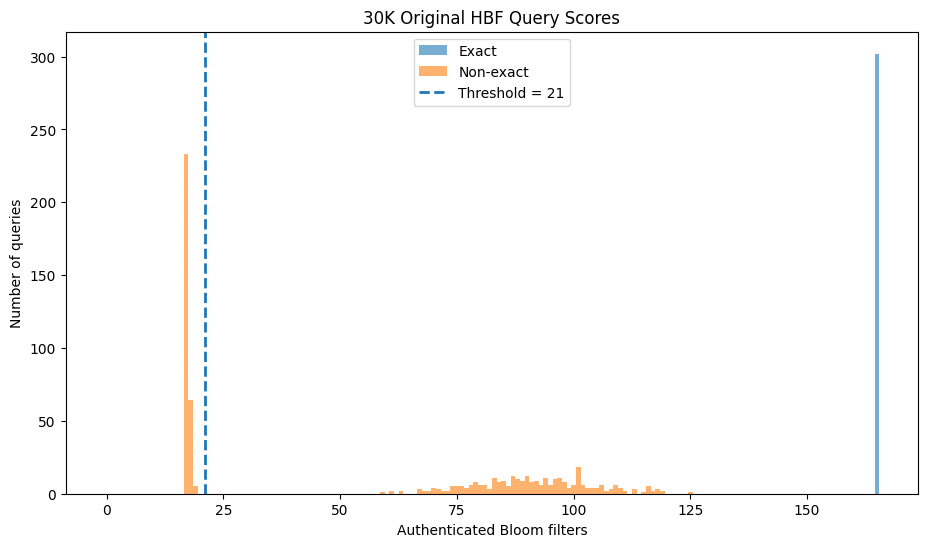

In [67]:
# ============================================================
# CELL 35 — SCORE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(11, 6)
)

exact_subset = results_30k_df[
    results_30k_df[
        "exact_enrollment_match"
    ]
]

nonexact_subset = results_30k_df[
    ~results_30k_df[
        "exact_enrollment_match"
    ]
]

plt.hist(
    exact_subset[
        "authenticated_bfs"
    ],
    bins=np.arange(0, 167) - 0.5,
    alpha=0.6,
    label="Exact"
)

plt.hist(
    nonexact_subset[
        "authenticated_bfs"
    ],
    bins=np.arange(0, 167) - 0.5,
    alpha=0.6,
    label="Non-exact"
)

plt.axvline(
    21,
    linestyle="--",
    linewidth=2,
    label="Threshold = 21"
)

plt.xlabel(
    "Authenticated Bloom filters"
)

plt.ylabel(
    "Number of queries"
)

plt.title(
    "30K Original HBF Query Scores"
)

plt.legend()

plt.show()

In [68]:
# ============================================================
# CELL 38 — ASSIGN GROUND-TRUTH LABELS FOR 906 QUERIES
# ============================================================

assert len(results_30k_df) == 906

results_30k_df = results_30k_df.copy()

results_30k_df["query_type"] = ""

results_30k_df.loc[
    0:301,
    "query_type"
] = "exact"

results_30k_df.loc[
    302:603,
    "query_type"
] = "noisy"

results_30k_df.loc[
    604:905,
    "query_type"
] = "impostor"


results_30k_df["ground_truth_member"] = (
    results_30k_df["query_type"]
    .isin([
        "exact",
        "noisy"
    ])
)


print("=" * 80)
print("QUERY GROUND TRUTH")
print("=" * 80)

print(
    results_30k_df[
        "query_type"
    ].value_counts()
)

print()

print(
    "Genuine queries :",
    results_30k_df[
        "ground_truth_member"
    ].sum()
)

print(
    "Impostor queries:",
    (
        ~results_30k_df[
            "ground_truth_member"
        ]
    ).sum()
)

QUERY GROUND TRUTH
query_type
exact       302
noisy       302
impostor    302
Name: count, dtype: int64

Genuine queries : 604
Impostor queries: 302


In [69]:
# ============================================================
# CELL 39 — METRICS AT ORIGINAL THRESHOLD > 21
# ============================================================

NT = 21

scores = (
    results_30k_df[
        "authenticated_bfs"
    ].to_numpy()
)

y_true = (
    results_30k_df[
        "ground_truth_member"
    ].to_numpy()
)

y_pred = (
    scores > NT
)

TP = int(
    np.sum(
        y_pred & y_true
    )
)

FN = int(
    np.sum(
        (~y_pred) & y_true
    )
)

FP = int(
    np.sum(
        y_pred & (~y_true)
    )
)

TN = int(
    np.sum(
        (~y_pred) & (~y_true)
    )
)


TAR = TP / (TP + FN)
FRR = FN / (TP + FN)

FAR = FP / (FP + TN)
TNR = TN / (FP + TN)

ACC = (
    (TP + TN)
    /
    (TP + TN + FP + FN)
)

BACC = (
    TAR + TNR
) / 2

PRECISION = (
    TP / (TP + FP)
    if (TP + FP) > 0
    else 0
)

F1 = (
    2 * PRECISION * TAR
    /
    (PRECISION + TAR)
    if (PRECISION + TAR) > 0
    else 0
)


print("=" * 80)
print("HBF PERFORMANCE AT ORIGINAL THRESHOLD > 21")
print("=" * 80)

print(f"TP  : {TP}")
print(f"FN  : {FN}")
print(f"FP  : {FP}")
print(f"TN  : {TN}")

print()

print(f"TAR / TPR : {TAR*100:.2f}%")
print(f"FRR / FNR : {FRR*100:.2f}%")

print(f"FAR / FPR : {FAR*100:.2f}%")
print(f"TNR       : {TNR*100:.2f}%")

print()

print(f"Accuracy  : {ACC*100:.2f}%")
print(f"BACC      : {BACC*100:.2f}%")
print(f"Precision : {PRECISION*100:.2f}%")
print(f"F1        : {F1*100:.2f}%")

HBF PERFORMANCE AT ORIGINAL THRESHOLD > 21
TP  : 604
FN  : 0
FP  : 0
TN  : 302

TAR / TPR : 100.00%
FRR / FNR : 0.00%
FAR / FPR : 0.00%
TNR       : 100.00%

Accuracy  : 100.00%
BACC      : 100.00%
Precision : 100.00%
F1        : 100.00%


In [70]:
# ============================================================
# CELL 40 — EXACT / NOISY / IMPOSTOR SCORE DISTRIBUTIONS
# ============================================================

category_summary = (
    results_30k_df
    .groupby(
        "query_type"
    )[
        "authenticated_bfs"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ])
)

display(
    category_summary.round(3)
)

,count,mean,std,min,median,max
query_type,,,,,,
exact,302,165.000,0.000,165,165.0,165
impostor,302,17.245,0.468,17,17.0,19
noisy,302,91.301,12.575,59,91.0,125


In [71]:
# ============================================================
# CELL 41 — COMPLETE THRESHOLD SWEEP
# ============================================================

sweep_rows = []

for t in range(
    0,
    166
):

    pred = (
        scores > t
    )

    TP = int(
        np.sum(
            pred & y_true
        )
    )

    FN = int(
        np.sum(
            (~pred) & y_true
        )
    )

    FP = int(
        np.sum(
            pred & (~y_true)
        )
    )

    TN = int(
        np.sum(
            (~pred) & (~y_true)
        )
    )


    TAR = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    FRR = (
        FN / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    FAR = (
        FP / (FP + TN)
        if (FP + TN) > 0
        else 0
    )

    TNR = (
        TN / (FP + TN)
        if (FP + TN) > 0
        else 0
    )

    ACC = (
        (TP + TN)
        /
        len(y_true)
    )

    BACC = (
        TAR + TNR
    ) / 2


    PRECISION = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else 0
    )

    F1 = (
        2 * PRECISION * TAR
        /
        (PRECISION + TAR)
        if (PRECISION + TAR) > 0
        else 0
    )


    sweep_rows.append({
        "threshold": t,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "TAR": TAR,
        "FRR": FRR,
        "FAR": FAR,
        "TNR": TNR,
        "ACC": ACC,
        "BACC": BACC,
        "Precision": PRECISION,
        "F1": F1
    })


sweep_30k_df = pd.DataFrame(
    sweep_rows
)

In [72]:
# ============================================================
# CELL 42 — APPROXIMATE EER
# ============================================================

sweep_30k_df[
    "eer_gap"
] = np.abs(
    sweep_30k_df["FAR"]
    -
    sweep_30k_df["FRR"]
)

eer_idx = (
    sweep_30k_df[
        "eer_gap"
    ].idxmin()
)

eer_row = (
    sweep_30k_df.loc[
        eer_idx
    ]
)

approx_eer = (
    eer_row["FAR"]
    +
    eer_row["FRR"]
) / 2


print("=" * 80)
print("APPROXIMATE EER")
print("=" * 80)

print(
    "Threshold :",
    int(
        eer_row[
            "threshold"
        ]
    )
)

print(
    f"FAR       : "
    f"{eer_row['FAR']*100:.2f}%"
)

print(
    f"FRR       : "
    f"{eer_row['FRR']*100:.2f}%"
)

print(
    f"EER       : "
    f"{approx_eer*100:.2f}%"
)

APPROXIMATE EER
Threshold : 19
FAR       : 0.00%
FRR       : 0.00%
EER       : 0.00%


In [73]:
# ============================================================
# CELL 43 — BEST OPERATING THRESHOLDS
# ============================================================

best_acc_idx = (
    sweep_30k_df[
        "ACC"
    ].idxmax()
)

best_bacc_idx = (
    sweep_30k_df[
        "BACC"
    ].idxmax()
)

best_acc = (
    sweep_30k_df.loc[
        best_acc_idx
    ]
)

best_bacc = (
    sweep_30k_df.loc[
        best_bacc_idx
    ]
)


print("=" * 80)
print("BEST ACCURACY")
print("=" * 80)

print(
    "Threshold :",
    int(
        best_acc["threshold"]
    )
)

print(
    f"ACC       : "
    f"{best_acc['ACC']*100:.2f}%"
)

print(
    f"TAR       : "
    f"{best_acc['TAR']*100:.2f}%"
)

print(
    f"FAR       : "
    f"{best_acc['FAR']*100:.2f}%"
)

print(
    f"FRR       : "
    f"{best_acc['FRR']*100:.2f}%"
)


print("\n" + "=" * 80)
print("BEST BALANCED ACCURACY")
print("=" * 80)

print(
    "Threshold :",
    int(
        best_bacc["threshold"]
    )
)

print(
    f"BACC      : "
    f"{best_bacc['BACC']*100:.2f}%"
)

print(
    f"ACC       : "
    f"{best_bacc['ACC']*100:.2f}%"
)

print(
    f"TAR       : "
    f"{best_bacc['TAR']*100:.2f}%"
)

print(
    f"FAR       : "
    f"{best_bacc['FAR']*100:.2f}%"
)

print(
    f"FRR       : "
    f"{best_bacc['FRR']*100:.2f}%"
)

BEST ACCURACY
Threshold : 19
ACC       : 100.00%
TAR       : 100.00%
FAR       : 0.00%
FRR       : 0.00%

BEST BALANCED ACCURACY
Threshold : 19
BACC      : 100.00%
ACC       : 100.00%
TAR       : 100.00%
FAR       : 0.00%
FRR       : 0.00%


ROC PERFORMANCE
AUC : 1.000000


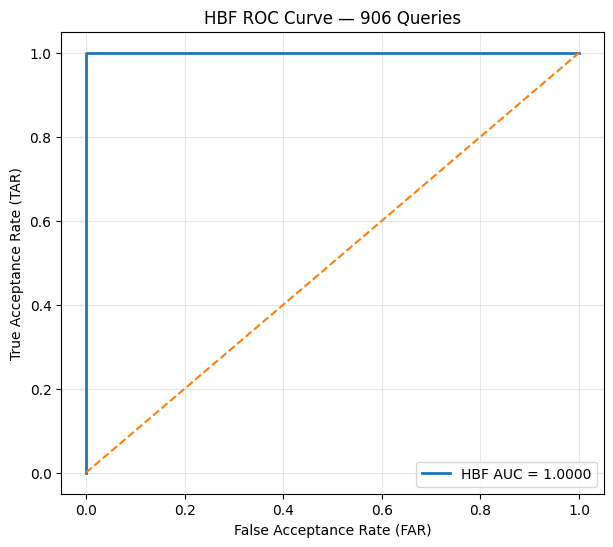

In [74]:
# ============================================================
# CELL 44 — ROC + AUC
# ============================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

auc = roc_auc_score(
    y_true.astype(int),
    scores
)

fpr, tpr, roc_thresholds = roc_curve(
    y_true.astype(int),
    scores
)


print("=" * 80)
print("ROC PERFORMANCE")
print("=" * 80)

print(
    f"AUC : {auc:.6f}"
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"HBF AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Acceptance Rate (FAR)"
)

plt.ylabel(
    "True Acceptance Rate (TAR)"
)

plt.title(
    "HBF ROC Curve — 906 Queries"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [75]:
# ============================================================
# CELL 45 — FINAL METRIC SUMMARY
# ============================================================

original_row = sweep_30k_df[
    sweep_30k_df[
        "threshold"
    ] == 21
].iloc[0]


final_metrics = pd.DataFrame([
    {
        "Operating Point":
            "Original GitHub Nt=21",

        "Threshold":
            21,

        "ACC (%)":
            original_row["ACC"] * 100,

        "BACC (%)":
            original_row["BACC"] * 100,

        "TAR (%)":
            original_row["TAR"] * 100,

        "FAR (%)":
            original_row["FAR"] * 100,

        "FRR (%)":
            original_row["FRR"] * 100,

        "TNR (%)":
            original_row["TNR"] * 100,

        "F1 (%)":
            original_row["F1"] * 100
    },

    {
        "Operating Point":
            "Approximate EER",

        "Threshold":
            int(
                eer_row["threshold"]
            ),

        "ACC (%)":
            eer_row["ACC"] * 100,

        "BACC (%)":
            eer_row["BACC"] * 100,

        "TAR (%)":
            eer_row["TAR"] * 100,

        "FAR (%)":
            eer_row["FAR"] * 100,

        "FRR (%)":
            eer_row["FRR"] * 100,

        "TNR (%)":
            eer_row["TNR"] * 100,

        "F1 (%)":
            eer_row["F1"] * 100
    },

    {
        "Operating Point":
            "Best BACC",

        "Threshold":
            int(
                best_bacc["threshold"]
            ),

        "ACC (%)":
            best_bacc["ACC"] * 100,

        "BACC (%)":
            best_bacc["BACC"] * 100,

        "TAR (%)":
            best_bacc["TAR"] * 100,

        "FAR (%)":
            best_bacc["FAR"] * 100,

        "FRR (%)":
            best_bacc["FRR"] * 100,

        "TNR (%)":
            best_bacc["TNR"] * 100,

        "F1 (%)":
            best_bacc["F1"] * 100
    }
])


display(
    final_metrics.round(2)
)

print(
    f"\nROC-AUC = {auc:.6f}"
)

,Operating Point,Threshold,ACC (%),BACC (%),TAR (%),FAR (%),FRR (%),TNR (%),F1 (%)
0,Original GitHub Nt=21,21,100.0,100.0,100.0,0.0,0.0,100.0,100.0
1,Approximate EER,19,100.0,100.0,100.0,0.0,0.0,100.0,100.0
2,Best BACC,19,100.0,100.0,100.0,0.0,0.0,100.0,100.0



ROC-AUC = 1.000000


# Final

In [76]:
# ============================================================
# REBUILD PREVIOUS FERETD QUERY SET
#
# KEEP:
#   400 FERETD exact
#   300 FERETD second/noisy
#
# REPLACE:
#   300 Faces94 impostors
# WITH:
#   300 impostors from new TXT query dataset
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")


# ------------------------------------------------------------
# Helper to find previous FERETD files
# ------------------------------------------------------------

def find_one(filename):

    matches = list(
        INPUT_ROOT.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}"
        )

    return matches[0]


# ------------------------------------------------------------
# Load PREVIOUS FERETD 1000-query set
# ------------------------------------------------------------

OLD_QUERY_FILE = find_one(
    "query_templates_4900bit.npy"
)

OLD_QUERY_META_FILE = find_one(
    "query_metadata.csv"
)


old_queries = np.load(
    OLD_QUERY_FILE
).astype(np.uint8)

old_query_meta = pd.read_csv(
    OLD_QUERY_META_FILE,
    dtype={"identity": str}
)


print("=" * 80)
print("PREVIOUS FERETD QUERY SET")
print("=" * 80)

print(
    "Shape:",
    old_queries.shape
)

print(
    old_query_meta[
        "query_type"
    ].value_counts()
)

PREVIOUS FERETD QUERY SET
Shape: (1000, 4900)
query_type
exact       400
second      300
impostor    300
Name: count, dtype: int64


In [77]:
# ============================================================
# KEEP ORIGINAL FERETD GENUINE QUERIES
# ============================================================

exact_indices = old_query_meta.index[
    old_query_meta["query_type"]
    == "exact"
].to_numpy()

second_indices = old_query_meta.index[
    old_query_meta["query_type"]
    == "second"
].to_numpy()


feret_exact = old_queries[
    exact_indices
]

feret_second = old_queries[
    second_indices
]


print(
    "FERET exact:",
    feret_exact.shape
)

print(
    "FERET second/noisy:",
    feret_second.shape
)


assert feret_exact.shape == (
    400,
    4900
)

assert feret_second.shape == (
    300,
    4900
)

FERET exact: (400, 4900)
FERET second/noisy: (300, 4900)


In [78]:
# ============================================================
# DIAGNOSE THE 906 NEW-TXT QUERIES
# ============================================================

from collections import Counter
import numpy as np
import pandas as pd

rows = []

enrollment_set_txt = set(orig_enrollment_data)

for i, q in enumerate(orig_query_data):

    q = str(q)

    rows.append({
        "query_index": i,
        "length": len(q),
        "is_binary": set(q) <= {"0", "1"},
        "is_4900": len(q) == 4900,
        "exact_in_30k_enrollment": q in enrollment_set_txt
    })

txt_query_audit = pd.DataFrame(rows)

print("=" * 80)
print("NEW TXT QUERY AUDIT")
print("=" * 80)

print("\nLength distribution:")
print(
    txt_query_audit["length"]
    .value_counts()
    .sort_index()
)

print("\nBinary / 4900 status:")
print(
    txt_query_audit[
        ["is_binary", "is_4900"]
    ].value_counts()
)

print("\nExact overlap with 30K enrollment:")
print(
    txt_query_audit[
        "exact_in_30k_enrollment"
    ].value_counts()
)

print("\n4900-bit queries:")
print(
    txt_query_audit[
        txt_query_audit["is_4900"]
    ][
        "exact_in_30k_enrollment"
    ].value_counts()
)

NEW TXT QUERY AUDIT

Length distribution:
length
10        1
11        3
12       27
13      271
4900    604
Name: count, dtype: int64

Binary / 4900 status:
is_binary  is_4900
True       True       604
False      False      302
Name: count, dtype: int64

Exact overlap with 30K enrollment:
exact_in_30k_enrollment
False    604
True     302
Name: count, dtype: int64

4900-bit queries:
exact_in_30k_enrollment
True     302
False    302
Name: count, dtype: int64


In [79]:
# ============================================================
# SHOW QUERY INDEX RANGES BY TYPE
# ============================================================

display(
    txt_query_audit[
        [
            "query_index",
            "length",
            "is_binary",
            "is_4900",
            "exact_in_30k_enrollment"
        ]
    ]
)

,query_index,length,is_binary,is_4900,exact_in_30k_enrollment
0,0,4900,True,True,True
1,1,4900,True,True,True
2,2,4900,True,True,True
3,3,4900,True,True,True
4,4,4900,True,True,True
...,...,...,...,...,...
901,901,13,False,False,False
902,902,13,False,False,False
903,903,13,False,False,False
904,904,13,False,False,False


In [80]:
# ============================================================
# SELECT 300 VALID EXTERNAL IMPOSTORS
# FROM NEW 30K ENROLLMENT DATASET
#
# These people are NOT enrolled in the FERETD HBF.
# ============================================================

valid_external_strings = [
    str(x)
    for x in orig_enrollment_data
    if (
        len(str(x)) == 4900
        and set(str(x)) <= {"0", "1"}
    )
]

print(
    "Valid 4900-bit templates available:",
    len(valid_external_strings)
)

assert len(valid_external_strings) >= 300


# Deterministic selection
txt_impostor_strings = (
    valid_external_strings[:300]
)


print(
    "Selected external impostors:",
    len(txt_impostor_strings)
)

print(
    "All length 4900:",
    all(
        len(x) == 4900
        for x in txt_impostor_strings
    )
)

print(
    "All binary:",
    all(
        set(x) <= {"0", "1"}
        for x in txt_impostor_strings
    )
)

Valid 4900-bit templates available: 30000
Selected external impostors: 300
All length 4900: True
All binary: True


In [81]:
# ============================================================
# GENUINE SEGMENT SURVIVAL — COUNTS + PERCENTAGES
# ============================================================
#
# For each segmentation size, report:
#
#   - Number of segments per template
#   - Mean bit flips per segment
#   - Average number of segments with 0 flips per genuine pair
#   - Average number of segments with <=1 flip
#   - Average number of segments with <=2 flips
#   - Average number of segments with <=3 flips
#   - Average number of segments with <=5 flips
#   - Corresponding percentages
#
# IMPORTANT:
# 0-flip segments are the ones that preserve the exact SHA hash.
# ============================================================

import numpy as np
import pandas as pd

P = 4900

SEGMENT_SIZES = [
    4,
    8,
    10,
    12,
    16,
    20,
    24,
    28,
    32,
    33,
    40,
    48,
    64,
    96,
    128,
    196,
    245,
    490
]


# ------------------------------------------------------------
# Genuine enrollment-query pairs
# ------------------------------------------------------------

genuine_pairs = []

for _, row in genuine_hd_cropped_df.iterrows():

    genuine_pairs.append(
        (
            int(row["enrollment_index"]),
            int(row["query_index"])
        )
    )


rows = []

# ============================================================
# TEST EACH SEGMENT SIZE
# ============================================================

for segment_size in SEGMENT_SIZES:

    n_segments = P // segment_size
    used_bits = n_segments * segment_size
    ignored_bits = P - used_bits

    # Store per-pair statistics
    pair_zero_counts = []
    pair_le1_counts = []
    pair_le2_counts = []
    pair_le3_counts = []
    pair_le5_counts = []

    all_hds = []

    for e_idx, q_idx in genuine_pairs:

        enroll = enrollment_bits_cropped[
            e_idx,
            :used_bits
        ].reshape(
            n_segments,
            segment_size
        )

        query = query_bits_cropped[
            q_idx,
            :used_bits
        ].reshape(
            n_segments,
            segment_size
        )

        # Hamming distance per segment
        hds = np.count_nonzero(
            enroll != query,
            axis=1
        )

        all_hds.extend(
            hds.tolist()
        )

        # ----------------------------------------------------
        # Counts PER genuine image pair
        # ----------------------------------------------------

        pair_zero_counts.append(
            np.sum(hds == 0)
        )

        pair_le1_counts.append(
            np.sum(hds <= 1)
        )

        pair_le2_counts.append(
            np.sum(hds <= 2)
        )

        pair_le3_counts.append(
            np.sum(hds <= 3)
        )

        pair_le5_counts.append(
            np.sum(hds <= 5)
        )

    all_hds = np.asarray(
        all_hds,
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Average count per genuine pair
    # --------------------------------------------------------

    avg_zero_count = np.mean(
        pair_zero_counts
    )

    avg_le1_count = np.mean(
        pair_le1_counts
    )

    avg_le2_count = np.mean(
        pair_le2_counts
    )

    avg_le3_count = np.mean(
        pair_le3_counts
    )

    avg_le5_count = np.mean(
        pair_le5_counts
    )

    # --------------------------------------------------------
    # Convert counts to percentage of all segments
    # --------------------------------------------------------

    zero_pct = (
        avg_zero_count
        / n_segments
        * 100
    )

    le1_pct = (
        avg_le1_count
        / n_segments
        * 100
    )

    le2_pct = (
        avg_le2_count
        / n_segments
        * 100
    )

    le3_pct = (
        avg_le3_count
        / n_segments
        * 100
    )

    le5_pct = (
        avg_le5_count
        / n_segments
        * 100
    )

    rows.append({

        "Segment size":
            segment_size,

        "Total segments":
            n_segments,

        "Bits ignored":
            ignored_bits,

        "Mean flips/segment":
            all_hds.mean(),

        "0-flip segments":
            avg_zero_count,

        "0-flip (%)":
            zero_pct,

        "<=1-flip segments":
            avg_le1_count,

        "<=1 flip (%)":
            le1_pct,

        "<=2-flip segments":
            avg_le2_count,

        "<=2 flip (%)":
            le2_pct,

        "<=3-flip segments":
            avg_le3_count,

        "<=3 flip (%)":
            le3_pct,

        "<=5-flip segments":
            avg_le5_count,

        "<=5 flip (%)":
            le5_pct
    })


segment_survival_count_df = pd.DataFrame(
    rows
)


# ------------------------------------------------------------
# Round values for display
# ------------------------------------------------------------

display_df = segment_survival_count_df.copy()

for col in [
    "Mean flips/segment",
    "0-flip segments",
    "0-flip (%)",
    "<=1-flip segments",
    "<=1 flip (%)",
    "<=2-flip segments",
    "<=2 flip (%)",
    "<=3-flip segments",
    "<=3 flip (%)",
    "<=5-flip segments",
    "<=5 flip (%)"
]:

    display_df[col] = (
        display_df[col]
        .round(2)
    )


print("=" * 130)
print("GENUINE SEGMENT SURVIVAL — AVERAGE COUNTS PER IMAGE PAIR")
print("=" * 130)

display(display_df)

NameError: name 'genuine_hd_cropped_df' is not defined